In [1]:
import numpy as np
from numpy.random import multivariate_normal
import pandas as pd
import os

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import make_scorer, roc_auc_score, average_precision_score, recall_score
from sklearn.model_selection import GridSearchCV
from sklearn.feature_selection import SequentialFeatureSelector, RFE
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier 

import scipy.io

import matplotlib.pyplot as plt
import matplotlib
# from matplotlib.font_manager import FontProperties
import seaborn as sns

import pickle as pkl
import math
import importlib
from sklearn.svm import OneClassSVM
from ocsvm_plus import OneClassSVM_plus

font_size = 18
large_font_size = 25
fig_size = 5.5

matplotlib.rcParams['text.usetex'] = True
matplotlib.rcParams['font.family'] = 'serif'
plt.rc('font', size=font_size)               # controls default text sizes
plt.rc('axes', titlesize=font_size)          # fontsize of the axes title
plt.rc('axes', labelsize=large_font_size)    # fontsize of the x and y labels
plt.rc('xtick', labelsize=font_size)         # fontsize of the tick labels
plt.rc('ytick', labelsize=font_size)         # fontsize of the tick labels
plt.rc('legend', fontsize=font_size)         # legend fontsize
plt.rc('figure', titlesize=large_font_size)  # fontsize of the figure title

ImportError: this version of pandas is incompatible with numpy < 1.16.5
your numpy version is 1.16.4.
Please upgrade numpy to >= 1.16.5 to use this pandas version

In [2]:
xx, yy = np.meshgrid(np.linspace(-3, 3, 500), np.linspace(-3, 3, 500))
np.random.seed(0)
print('start')
X = 0.5*np.random.randn(1000, 2)
X[-2:, :] = [[-2.5, 0], [2.5, 0]] # set left and right outliers

# OCSVM
# ocsvm = OneClassSVM(nu=0.5, gamma=0.1).fit(X)

# OCSVM+
left = X[:, 0] < 0
X_star = np.empty((X.shape[0], 1))
X_star[~left] = 0.1*np.random.randn(X[~left].shape[0], 1) # right points spaced closely in privileged space
X_star[left] = (2*np.random.rand(X[left].shape[0], 1)-1) * 100
X_star[left] = X_star[left] + 10*np.sign(X_star[left])    # left points spaced chaotically in privileged space, (-110, -10) or (10, 110)

start


# Example 1

In [4]:
xx, yy = np.meshgrid(np.linspace(-3, 3, 500), np.linspace(-3, 3, 500))
np.random.seed(0)
X = 0.5*np.random.randn(1000, 2)
X[-2:, :] = [[-2.5, 0], [2.5, 0]] # set left and right outliers

# OCSVM
ocsvm = OneClassSVM(nu=0.5, gamma=0.1).fit(X)
display('finish OneClassSVM')

# OCSVM+
left = X[:, 0] < 0
X_star = np.empty((X.shape[0], 1))
X_star[~left] = 0.1*np.random.randn(X[~left].shape[0], 1) # right points spaced closely in privileged space
X_star[left] = (2*np.random.rand(X[left].shape[0], 1)-1) * 100
X_star[left] = X_star[left] + 10*np.sign(X_star[left])    # left points spaced chaotically in privileged space, (-110, -10) or (10, 110)
print('start')
ocsvm_plus = OneClassSVM_plus(n_features=2, nu=0.5, gamma=0.1, kernel_gamma=0.1, kernel_star_gamma=0.1, alg='cvxopt').fit(np.hstack((X, X_star)))
print('finish')

# for title, model in [('One-Class nu-SVM', ocsvm),
#                      ('One-Class nu-SVM+ when left points \n are anomalies in privileged space', ocsvm_plus)]:
#     plt.figure(figsize=[fig_size, fig_size])
# #     plt.gca().set_title(title)

#     print('start df', title)
#     Z = model.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
#     print('finish df', title)
#     plt.contourf(xx, yy, Z, levels=np.linspace(Z.min(), 0, 7), cmap=plt.cm.PuBu)
#     plt.contourf(xx, yy, Z, levels=[0, Z.max()], colors='indianred')    
#     plt.contour(xx, yy, Z, levels=[0], linewidths=2, colors='darkred')

#     if 'One-Class nu-SVM+' in title:
#         if model.fit_status_:
#             plt.scatter(X[model.alpha_support_, 0], X[model.alpha_support_, 1], c='r',  s=100, edgecolors='r', label=r'\textbf{$\alpha_k>0$}', marker='s')

#             delta0 = [i for i in range(X.shape[0]) if model.deltas_[i] < 1e-05 and i not in model.delta_support_]
#             plt.scatter(X[delta0, 0], X[delta0, 1], c='w', s=60, edgecolors='k', label=r'\textbf{$\delta_k=0$}')

#             plt.scatter(X[model.delta_support_, 0], X[model.delta_support_, 1], c='g', s=70, edgecolors='k', label=r'\textbf{$0<\delta_k<1$}')

#             delta1 = [i for i in range(X.shape[0]) if model.deltas_[i] > 1-1e-05 and i not in model.delta_support_]
#             plt.scatter(X[delta1, 0], X[delta1, 1], c='orange', s=70, edgecolors='k', label=r'\textbf{$\delta_k=1$}')
#     else: # OCSVM
#         plt.scatter(X[model.support_, 0], X[model.support_, 1], c='r',  s=80, edgecolors='k', label=r'\textbf{$\alpha_k>0$}', marker='s')
        
#         alpha0 = [i for i in range(X.shape[0]) if i not in model.support_]
#         plt.scatter(X[alpha0, 0], X[alpha0, 1], c='lightgrey',  s=70, edgecolors='k', label=r'\textbf{$\alpha_k=0$}')
        
#     plt.gca().legend(fontsize=font_size, loc='upper left', ncol=2)
    
    
# # # additional plot
# # model = OneClassSVM_plus(n_features=2, nu=0.5, gamma=10**4, kernel_gamma=0.1, kernel_star_gamma=0.1, tau=1e-5, alg='best_step_2d').fit(np.hstack((X, X_star)))
# # plt.figure(figsize=[fig_size, fig_size])
# # # plt.gca().set_title('One-Class nu-SVM+ \n with high privileged regularization '+r'\textbf{$\gamma$}')

# # Z = model.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
# # plt.contourf(xx, yy, Z, levels=np.linspace(Z.min(), 0, 7), cmap=plt.cm.PuBu)
# # plt.contourf(xx, yy, Z, levels=[0, Z.max()], colors='indianred')
# # plt.contour(xx, yy, Z, levels=[0], linewidths=2, colors='darkred')

# # plt.scatter(X[model.alpha_support_, 0], X[model.alpha_support_, 1], c='r',  s=100, edgecolors='r', label=r'\textbf{$\alpha_k>0$}', marker='s')

# # delta0 = [i for i in range(X.shape[0]) if model.deltas_[i] < 1e-05 and i not in model.delta_support_]
# # plt.scatter(X[delta0, 0], X[delta0, 1], c='w', s=60, edgecolors='k', label=r'\textbf{$\delta_k=0$}')

# # plt.scatter(X[model.delta_support_, 0], X[model.delta_support_, 1], c='g', s=70, edgecolors='k', label=r'\textbf{$0<\delta_k<1$}')

# # delta1 = [i for i in range(X.shape[0]) if model.deltas_[i] > 1-1e-05 and i not in model.delta_support_]
# # plt.scatter(X[delta1, 0], X[delta1, 1], c='orange', s=70, edgecolors='k', label=r'$\delta_k=1$')

# # plt.gca().legend(fontsize=font_size, loc='upper left', ncol=2)

'finish OneClassSVM'

start
     pcost       dcost       gap    pres   dres
 0:  5.8261e+04  2.5237e+03  2e+06  2e+01  2e+03
 1:  7.1626e+04  4.8527e+03  5e+05  4e+00  3e+02
 2:  8.1934e+04  2.8246e+04  8e+04  4e-01  3e+01
 3:  8.1177e+04  5.5919e+04  3e+04  1e-01  1e+01
 4:  8.0770e+04  6.4574e+04  2e+04  2e-02  2e+00
 5:  7.8027e+04  7.2263e+04  6e+03  7e-03  5e-01
 6:  7.6734e+04  7.4858e+04  2e+03  2e-03  1e-01
 7:  7.6217e+04  7.5698e+04  5e+02  3e-04  3e-02
 8:  7.6068e+04  7.5903e+04  2e+02  7e-05  6e-03
 9:  7.6018e+04  7.5962e+04  6e+01  1e-05  1e-03
10:  7.5998e+04  7.5981e+04  2e+01  3e-06  3e-04
11:  7.5991e+04  7.5987e+04  3e+00  1e-07  1e-05
12:  7.5990e+04  7.5988e+04  2e+00  8e-08  6e-06
13:  7.5989e+04  7.5988e+04  1e+00  4e-08  3e-06
14:  7.5989e+04  7.5989e+04  5e-01  1e-08  8e-07
15:  7.5989e+04  7.5989e+04  9e-02  2e-15  2e-08
16:  7.5989e+04  7.5989e+04  8e-03  5e-16  2e-08
Optimal solution found.
finish


In [2]:
import os
os.environ['OMP_NUM_THREADS']

KeyError: 'OMP_NUM_THREADS'

In [9]:
xx, yy = np.meshgrid(np.linspace(-3, 3, 500), np.linspace(-3, 3, 500))
np.random.seed(0)
X = 0.5*np.random.randn(200, 2)
X[-2:, :] = [[-2.5, 0], [2.5, 0]] # set left and right outliers

# OCSVM+
left = X[:, 0] < 0
X_star = np.empty((X.shape[0], 1))
X_star[~left] = 0.1*np.random.randn(X[~left].shape[0], 1) # right points spaced closely in privileged space
X_star[left] = (2*np.random.rand(X[left].shape[0], 1)-1) * 100
X_star[left] = X_star[left] + 10*np.sign(X_star[left])    # left points spaced chaotically in privileged space, (-110, -10) or (10, 110)
ocsvm_plus = OneClassSVM_plus(n_features=2, nu=0.5, gamma=0.1, kernel_gamma=0.1, kernel_star_gamma=0.1, alg='best_step_2d').fit(np.hstack((X, X_star)))
print(ocsvm_plus.alphas_, ocsvm_plus.deltas_, ocsvm_plus.rho_, ocsvm_plus.b_star_)
ocsvm_plus = OneClassSVM_plus(n_features=2, nu=0.5, gamma=0.1, kernel_gamma=0.1, kernel_star_gamma=0.1, alg='cvxopt').fit(np.hstack((X, X_star)))
print(ocsvm_plus.alphas_, ocsvm_plus.deltas_, ocsvm_plus.rho_, ocsvm_plus.b_star_)
# del ocsvm_plus

[0.00000000e+00 1.14890271e+01 0.00000000e+00 0.00000000e+00
 0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00 0.00000000e+00 2.47810911e-01 0.00000000e+00
 0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 1.05075110e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00 2.36128040e+00 0.00000000e+00 1.35164228e-03
 1.00327916e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00 1.40594573e-01 0.00000000e+00 0.00000000e+00
 0.00000000e+00 1.00058455e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 2.79261913e-02 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00 1.62760616e-03 0.00000000e+00 0.00000000e+00
 0.00000000e+00 0.00000000e+00 0.00000000e+00 5.34761172e-01
 5.22623878e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 1.14944184e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00 0.000000

## quality relative to hyperparameters

In [144]:
np.random.seed(0)
X = 0.5*np.random.randn(200, 2)
X[-2:, :] = [[-2.5, 0], [2.5, 0]] # set left and right outliers
left = X[:, 0] < 0
X_star = np.empty((X.shape[0], 1))
X_star[~left] = 0.1*np.random.randn(X[~left].shape[0], 1) # right points spaced closely in privileged space
X_star[left] = (2*np.random.rand(X[left].shape[0], 1)-1) * 100
X_star[left] = X_star[left] + 10*np.sign(X_star[left])    # left points spaced chaotically in privileged space, (-110, -10) or (10, 110)

y_true = np.array([1 if v > 0 else -1 for v in X[:, 0]])

file = 'experiment1_score_hyperparams.pkl'
if os.path.isfile(file):
    res = pkl.load(open(file, 'rb'))
else:
    res = []
    
for gamma in [0.001, 0.005, 0.01, 0.05, 0.1, 0.5, 1, 5, 9, 10, 14, 50, 100, 500, 10**3]:
    for kernel_star_gamma in [0.001, 0.005, 0.01, 0.05, 0.1, 0.5, 1, 9, 10, 14, 50, 100, 500, 10**3, 5*10**3, 10**4]:
        if (gamma, kernel_star_gamma) not in [(g, kg) for g, kg, sc in res]:
            for tau in [1e-3, 1e-4, 1e-5, 1e-6, 1e-7, 1e-8]:
                ocsvm_plus = OneClassSVM_plus(n_features=2, nu=0.5, 
                                              gamma=gamma, kernel_gamma=0.1,
                                              kernel_star_gamma=kernel_star_gamma, tau=tau).fit(np.hstack((X, X_star)))
                if ocsvm_plus.fit_status_:
                    print('gamma=', gamma, 'kernel_star_gamma=', kernel_star_gamma, 'tau=', tau, 'is ok')
                    break
                else:
                    print('gamma=', gamma, 'kernel_star_gamma=', kernel_star_gamma, 'tau=', tau, 'is not enough')
            score = recall_score(-y_true, -ocsvm_plus.predict(X))
            res.append((gamma, kernel_star_gamma, score))
            print('score=', score)
            pkl.dump(res, open(file, "wb"))
res

[(0.01, 0.1, 0.18584070796460178),
 (0.001, 0.1, 0.20353982300884957),
 (0.1, 0.1, 0.18584070796460178),
 (1, 0.1, 0.168141592920354),
 (10, 0.1, 0.13274336283185842),
 (100, 0.1, 0.05309734513274336),
 (0.001, 0.001, 0.05309734513274336),
 (0.001, 0.01, 0.11504424778761062),
 (0.001, 1, 0.21238938053097345),
 (0.001, 10, 0.2831858407079646),
 (0.001, 100, 0.34513274336283184),
 (0.001, 9, 0.26548672566371684),
 (0.001, 14, 0.26548672566371684),
 (0.01, 0.001, 0.05309734513274336),
 (0.01, 0.01, 0.10619469026548672),
 (0.01, 1, 0.21238938053097345),
 (0.01, 10, 0.25663716814159293),
 (0.01, 100, 0.3185840707964602),
 (0.01, 9, 0.25663716814159293),
 (0.01, 14, 0.2743362831858407),
 (0.1, 0.001, 0.05309734513274336),
 (0.1, 0.01, 0.10619469026548672),
 (0.1, 1, 0.21238938053097345),
 (0.1, 10, 0.24778761061946902),
 (0.1, 100, 0.30973451327433627),
 (0.1, 9, 0.25663716814159293),
 (0.1, 14, 0.2831858407079646),
 (1, 0.001, 0.035398230088495575),
 (1, 0.01, 0.09734513274336283),
 (1, 1, 

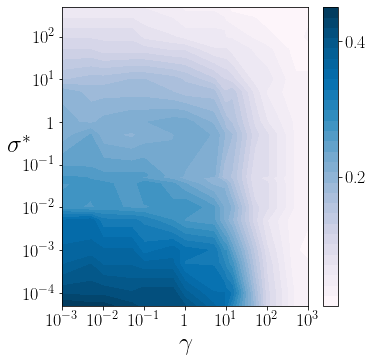

In [145]:
res = pkl.load(open('experiment1_score_hyperparams.pkl', 'rb'))
gamma, kernel_star_gamma, score = zip(*res)

gg = np.array(sorted(set(gamma)))
kgg = np.array(sorted(set(kernel_star_gamma), reverse=True))
sgg = 0.5/kgg

ss_ = {(g, kg): s for g, kg, s in res}
ss = np.empty([len(kgg), len(gg)])
for ig, g in enumerate(gg):
    for ikg, kg in enumerate(kgg):
        ss[ikg, ig] = ss_[(g, kg)]

plt.figure(figsize=[fig_size, fig_size])        
h0 = plt.contourf(np.log10(gg), np.log10(sgg), ss, levels=np.linspace(ss.min(), ss.max(), 30), cmap=plt.cm.PuBu)
h = plt.colorbar(h0, format='%.1f')
h.ax.locator_params(nbins=3)
h.set_ticks([0, 0.2, 0.4])
for t in h.ax.get_yticklabels():
    t.set_usetex(True)
    
# plt.title('Anomaly detection recall')
rng = range(int(min(np.log10(gg))), int(max(np.log10(gg)))+1)
plt.xticks(rng, [r'$10^{'+str(i)+'}$' if i != 0 else r'$1$' for i in rng])

rng = range(int(min(np.log10(sgg))), int(max(np.log10(sgg)))+1)
plt.yticks(rng, [r'$10^{'+str(i)+'}$' if i != 0 else r'$1$' for i in rng])

plt.xlabel(r'\textbf{$\gamma$}')
plt.ylabel(r'\textbf{$\sigma^*$}', rotation='horizontal')

plt.savefig('expr1_3.png')
plt.show()

# Shuttle dataset anomaly detection

In [146]:
data = scipy.io.loadmat('shuttle.mat')
X = data['X']
y = data['y'].ravel()

In [147]:
Xn = StandardScaler().fit_transform(X)
Xn

array([[ 2.38259739e-01,  2.48766443e-01, -9.15031367e-01, ...,
        -8.33004945e-01, -1.40284857e-02,  4.94218240e-01],
       [ 4.71268936e-01,  7.55312322e-04, -3.51805070e-01, ...,
        -6.84263691e-01, -8.89010354e-01, -3.47859307e-01],
       [-7.71446782e-01,  7.55312322e-04, -1.02767663e+00, ...,
         1.33813202e-01, -1.40284857e-02, -9.52360429e-02],
       ...,
       [ 1.60590006e-01,  7.55312322e-04,  2.11421228e-01, ...,
        -1.49280511e-02, -3.54299212e-01, -3.47859307e-01],
       [ 2.56835171e+00,  7.55312322e-04, -1.26514551e-01, ...,
        -2.54352936e+00,  3.48589899e+00,  4.45198271e+00],
       [-7.71446782e-01,  7.55312322e-04,  2.01374538e+00, ...,
         2.06744950e+00,  1.78454535e+00,  4.10010486e-01]])

### correlations

In [148]:
pd.DataFrame(Xn).cov()

,0,1,2,3,4,5,6,7,8
0,1.000020,0.072189,0.278987,-0.008960,0.011396,0.000247,-0.774826,0.116361,0.538118
1,0.072189,1.000020,-0.003416,-0.000039,-0.000361,-0.001144,-0.071081,-0.001083,0.039198
2,0.278987,-0.003416,1.000020,0.046123,0.173421,0.001843,0.389778,0.261813,0.005554
3,-0.008960,-0.000039,0.046123,1.000020,0.013857,0.073051,0.039384,0.006423,-0.016454
4,0.011396,-0.000361,0.173421,0.013857,1.000020,0.088905,0.100675,-0.904465,-0.835874
5,0.000247,-0.001144,0.001843,0.073051,0.088905,1.000020,0.000979,-0.085654,-0.074247
6,-0.774826,-0.071081,0.389778,0.039384,0.100675,0.000979,1.000020,0.063190,-0.510337
7,0.116361,-0.001083,0.261813,0.006423,-0.904465,-0.085654,0.063190,1.000020,0.825539
8,0.538118,0.039198,0.005554,-0.016454,-0.835874,-0.074247,-0.510337,0.825539,1.000020


### anomality heatmaps

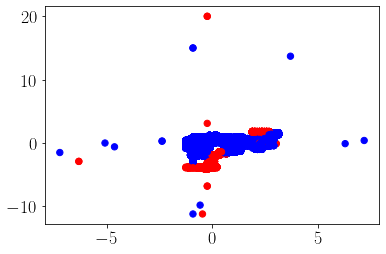

In [149]:
plt.scatter(Xn[:, 2], Xn[:, 4], c=['r' if i == 1 else 'b' for i in y], s=40)
plt.show()

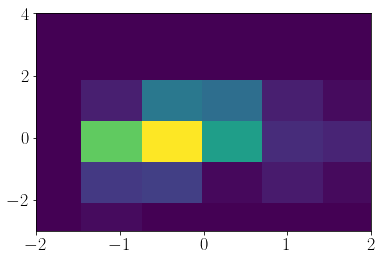

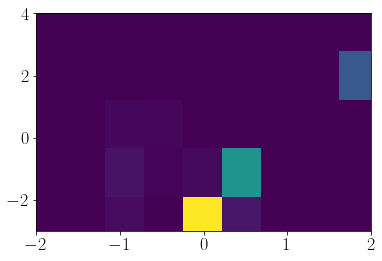

In [150]:
plt.figure()
plt.hist2d(Xn[(y==0).ravel(), 2], Xn[(y==0).ravel(), 4], bins=20)
plt.xlim([-2, 2])
plt.ylim([-3, 4])


plt.figure()
plt.hist2d(Xn[(y==1).ravel(), 2], Xn[(y==1).ravel(), 4], bins=20)
plt.xlim([-2, 2])
plt.ylim([-3, 4])

plt.show()

### what features characterize anomality

In [151]:
clf = ExtraTreesClassifier(
                           n_estimators = 100,
                           max_depth = 5,
                           bootstrap = True,
                           oob_score = True,
                           random_state = 0
                          )
clf_sfs = SequentialFeatureSelector(clf, n_features_to_select=7, cv=3, n_jobs=-1)
# clf_sfs = RFE(clf, n_features_to_select=7, step=1)

clf_sfs.fit(Xn, y);
f_support = [i for i, v in enumerate(clf_sfs.get_support()) if v]
print(f_support)

[0, 1, 4, 5, 6, 7, 8]


### quality metric with respect to kernel_gamma

In [152]:
file = 'experiment_shuttle.pkl'
nu = 0.1
n_folds = 10

cv = []
for i in range(n_folds):
    y_ = pd.Series(y)
    y_train = list(y_[y_ == 0][::10][i::n_folds].index) + list(y_[y_ == 1][::10][i::n_folds][::math.ceil(1/nu)].index)
#     y_train = list(y_[y_ == 0][::5][i::n_folds].index)
    y_test = [i for i in y_.index if i not in y_train]
    cv.append((y_train, y_test))

def average_precision_score_inv(y, y_pred, **kwargs): # anomaly is a positive class
    return average_precision_score(y, -y_pred, **kwargs)

def print_cv_results(gscv):
    best_params = gscv.best_params_
    best_score_std = gscv.cv_results_['std_test_score'][gscv.best_index_]
    best_param_time = gscv.cv_results_['mean_fit_time'][gscv.best_index_]
    best_param_time_std = gscv.cv_results_['std_fit_time'][gscv.best_index_]
    print('params:', best_params, 
          'time:', [best_param_time-best_param_time_std, best_param_time+best_param_time_std],
          'score:', [gscv.best_score_-best_score_std, gscv.best_score_+best_score_std], 
          'score_std:', best_score_std)
    
for gamma in [5e-4, 5e-3, 5e-2, 0.3, 5e-1, 2.5, 3, 5e+0]:
    if os.path.isfile(file):
        ress = pkl.load(open(file, 'rb'))
    else:
        ress = dict()
        
    if gamma in ress:
        continue
    res = dict()
    
    ocsvm_worst = GridSearchCV(OneClassSVM(),
                               param_grid={'nu': np.linspace(0.1, 0.99, 10), 'gamma': [gamma]},
                               scoring=make_scorer(average_precision_score_inv, needs_threshold=True),
                               cv=cv,
                               n_jobs=-1,
                               refit = False)
    ocsvm_worst.fit(Xn[:, [2, 4]], y)
    print_cv_results(ocsvm_worst)
    res['worst'] = [ocsvm_worst.cv_results_, ocsvm_worst.best_index_]
    
    ocsvm_plus = GridSearchCV(OneClassSVM_plus(n_features=2, random_seed=0),
                              param_grid={
                                          'nu': np.linspace(0.1, 0.99, 10),
                                          'gamma': [1e-2, 1e-1, 1, 1e+1, 1e+2, 1e+3],
                                          'kernel_gamma': [gamma],
                                          'kernel_star_gamma': [1e-4, 0.001, 0.01, 0.1, 1]
                                         },
                              scoring=make_scorer(average_precision_score_inv, needs_threshold=True),
                              cv=cv,
                              n_jobs=-1,
                              refit = False)
    ocsvm_plus.fit(np.hstack((Xn[:, [2, 4]], Xn[:, [0, 6, 7, 8]])), y)
    print_cv_results(ocsvm_plus)
    res['plus'] = [ocsvm_plus.cv_results_, ocsvm_plus.best_index_]

    ocsvm_best = GridSearchCV(OneClassSVM(),
                              param_grid={'nu': np.linspace(0.1, 0.99, 10), 'gamma': [gamma]},
                              scoring=make_scorer(average_precision_score_inv, needs_threshold=True),
                              cv=cv,
                              n_jobs=-1,
                              refit = False)
    ocsvm_best.fit(np.hstack((Xn[:, [2, 4]], Xn[:, [0, 6, 7, 8]])), y)
    print_cv_results(ocsvm_best)
    res['best'] = [ocsvm_best.cv_results_, ocsvm_best.best_index_]
    
    ress[gamma] = res
    pkl.dump(ress, open(file, "wb"))

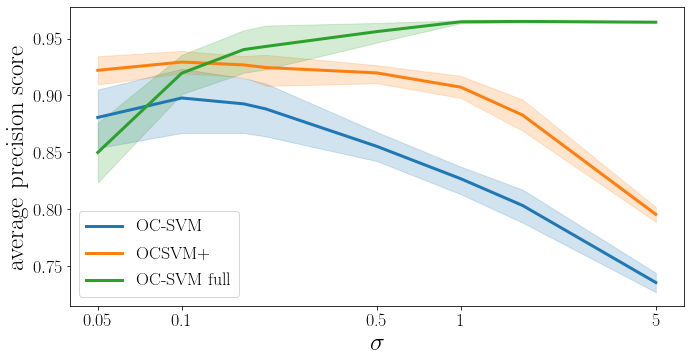

In [153]:
ress = pkl.load(open('experiment_shuttle.pkl', 'rb'))

def fexp(f):
    return int(math.floor(math.log10(abs(f)))) if f != 0 else 0
def fman(f):
    return f/10**fexp(f)

res = []
for gamma, v in ress.items():
    for model in v:
        cv_results, best_index = ress[gamma][model]
        score = [cv_results[k][best_index] for k in cv_results.keys() if 'split' in k and '_test_score' in k]
        time = cv_results['mean_fit_time'][best_index]
        time_std = cv_results['std_fit_time'][best_index]
        time = time + time_std*np.random.randn(len(score))
        for s, t in zip(score, time):
            sigma = 0.5/gamma
            res.append({'kernel sigma': sigma,
                        'sigma log': math.log2(sigma),
                        'model': 
                        {'worst': 'OC-SVM', 
                         'plus': 'OCSVM+', 
                         'best': 'OC-SVM full'}[model], 
                         'average precision score': s, 
                         'time': t})
res=pd.DataFrame(res)
res

plt.figure(figsize=(2*fig_size, fig_size))
ax = plt.gca()
ax = sns.lineplot(x="sigma log", y="average precision score", hue="model", data=res[res['kernel sigma'] < 10], linewidth=3)
handles, labels = ax.get_legend_handles_labels()
h = ax.legend(handles=handles[1:], labels=labels[1:])
vv = [0.05, 0.1, 0.5, 1, 5]
ax.set_xticks([math.log2(v) for v in vv])
ax.set_xticklabels(vv)
for line in h.get_lines():
    line.set_linewidth(3)

plt.xlabel(r'\textbf{$\sigma$}')
plt.show()

# Performance tests. Compare with CVXOPT

In [25]:
from cvxopt import matrix, solvers

In [141]:
I = matrix([[1.0, 0.0], [0.0, 1.0]])
q = matrix([0.0, 0.0])
G = matrix([[-1.0, 0.0], [0.0, -1.0]])
h = matrix([0.0, 0.0])
A = matrix([[1.0], [1.0]])
b = matrix([1.0])
r = solvers.qp(I, q, G, h, A, b)['x']
np.array(r)

     pcost       dcost       gap    pres   dres
 0:  2.5000e-01 -7.5000e-01  1e+00  2e-16  2e+00
 1:  2.5000e-01  2.4000e-01  1e-02  2e-16  2e-02
 2:  2.5000e-01  2.4990e-01  1e-04  3e-16  2e-04
 3:  2.5000e-01  2.5000e-01  1e-06  0e+00  2e-06
 4:  2.5000e-01  2.5000e-01  1e-08  0e+00  2e-08
Optimal solution found.


array([[0.5],
       [0.5]])

In [91]:
A = np.array([[1, 2], [3, 4]], dtype=float)
B = matrix(A)
del A
B[0, 1] = 10
print(B)

# A = matrix([[1.0], [1.0]])
# A.size

[ 1.00e+00  1.00e+01]
[ 3.00e+00  4.00e+00]



In [66]:
q = matrix([[0.0, 0.0]])
q.size, pbar.typecode

((2, 1), 'd')

In [51]:
n = 4
S = matrix([[ 4e-2,  6e-3, -4e-3,    0.0 ],
            [ 6e-3,  1e-2,  0.0,     0.0 ],
            [-4e-3,  0.0,   2.5e-3,  0.0 ],
            [ 0.0,   0.0,   0.0,     0.0 ]])
pbar = matrix([.12, .10, .07, .03])
G = matrix(0.0, (n,n))
G[::n+1] = -1.0
h = matrix(0.0, (n,1))
# A = matrix(1.0, (1,n))
# b = matrix(1.0)

solvers.qp(S, -pbar, G, h)['x']

     pcost       dcost       gap    pres   dres
 0: -2.9108e-02 -3.5016e-01  3e-01  0e+00  2e+00
 1: -3.4329e-02 -4.5947e-02  1e-02  3e-17  2e-01
 2: -2.5827e-01 -4.0360e-01  1e-01  0e+00  2e-01
 3: -1.7478e+00 -4.6754e+00  3e+00  7e-15  2e-01
 4: -1.6590e+00 -5.2092e+00  4e+00  4e-14  6e-02
 5: -1.1151e+01 -1.4679e+01  4e+00  4e-14  6e-02
 6: -6.2960e+04 -6.2963e+04  4e+00  5e-10  6e-02
 7: -4.1206e+10 -4.1206e+10  6e+02  5e-14  6e-02
 8: -2.6969e+18 -2.6969e+18  4e+08  3e+04  6e-02
 9: -1.7651e+28 -1.7651e+28  3e+16  7e+13  6e-02
10: -1.1553e+40 -1.1553e+40  2e+26  8e+25  6e-02
11: -7.5084e+53 -7.5084e+53  1e+38  5e+39  6e-02
12: -4.1676e+69 -4.1676e+69  6e+51  2e+55  6e-02
13: -1.8215e+105 -1.8215e+105  3e+87  8e+90  3e-02
14: -1.2571e+121 -1.2571e+121  2e+101  8e+00  3e-02
15: -5.4942e+160 -5.4942e+160  8e+140 4e+146  1e-01
16: -2.4013e+200 -2.4013e+200  4e+180    inf  5e-02
17: -1.0495e+240 -1.0495e+240  2e+220  1e+00  3e-02
18: -4.5872e+279 -4.5872e+279  7e+259    inf  3e-02


ValueError: domain error

In [86]:
smo = False
isinstance(smo, bool)

True

In [ ]:
xx, yy = np.meshgrid(np.linspace(-3, 3, 500), np.linspace(-3, 3, 500))
np.random.seed(0)
X = 0.5*np.random.randn(200, 2)
X[-2:, :] = [[-2.5, 0], [2.5, 0]] # set left and right outliers

# OCSVM+
left = X[:, 0] < 0
X_star = np.empty((X.shape[0], 1))
X_star[~left] = 0.1*np.random.randn(X[~left].shape[0], 1) # right points spaced closely in privileged space
X_star[left] = (2*np.random.rand(X[left].shape[0], 1)-1) * 100
X_star[left] = X_star[left] + 10*np.sign(X_star[left])    # left points spaced chaotically in privileged space, (-110, -10) or (10, 110)
ocsvm_plus = OneClassSVM_plus(n_features=2, nu=0.5, gamma=0.1, kernel_gamma=0.1, kernel_star_gamma=0.1)

ocsvm_plus.fit(np.hstack((X, X_star)))
# ocsvm_plus_CVXOPT = OneClassSVM_plus(n_features=2, nu=0.5, gamma=0.1, kernel_gamma=0.1, kernel_star_gamma=0.1, alg='cvxopt').fit(np.hstack((X, X_star)))

# for title, model in [('OC-SVM+ SMO', ocsvm_plus),
#                      ('OC-SVM+ CVXOPT', ocsvm_plus_CVXOPT)]:
# for title, model in [('OC-SVM+ SMO', ocsvm_plus)]:
#     plt.figure(figsize=[fig_size, fig_size])

#     Z = model.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
#     plt.contourf(xx, yy, Z, levels=np.linspace(Z.min(), 0, 7), cmap=plt.cm.PuBu)
#     plt.contourf(xx, yy, Z, levels=[0, Z.max()], colors='indianred')    
#     plt.contour(xx, yy, Z, levels=[0], linewidths=2, colors='darkred')

#     if model.fit_status_:
#         plt.scatter(X[model.alpha_support_, 0], X[model.alpha_support_, 1], c='r',  s=100, edgecolors='r', label=r'\textbf{$\alpha_k>0$}', marker='s')

#         delta0 = [i for i in range(X.shape[0]) if model.deltas_[i] < 1e-05 and i not in model.delta_support_]
#         plt.scatter(X[delta0, 0], X[delta0, 1], c='w', s=60, edgecolors='k', label=r'\textbf{$\delta_k=0$}')

#         plt.scatter(X[model.delta_support_, 0], X[model.delta_support_, 1], c='g', s=70, edgecolors='k', label=r'\textbf{$0<\delta_k<1$}')

#         delta1 = [i for i in range(X.shape[0]) if model.deltas_[i] > 1-1e-05 and i not in model.delta_support_]
#         plt.scatter(X[delta1, 0], X[delta1, 1], c='orange', s=70, edgecolors='k', label=r'\textbf{$\delta_k=1$}')
            
#     plt.gca().legend(fontsize=font_size, loc='upper left', ncol=2)